# Frecuencias naturales del puente Z24 en cada medición del monitoreo (EMS)

Este notebook calcula las frecuencias naturales del puente Z24 en cada una de las 5653 mediciones horarias del monitoreo continuo (EMS), del 10.11.1997 al 10.09.1998. El periodo incluye unos 9 meses con el puente sano y el último mes, en que se le aplicaron los daños progresivos (desde el 11.08.1998).

Las frecuencias se identifican con el método de descomposición en el dominio de la frecuencia (FDD, *Frequency Domain Decomposition*), siguiendo cada modo con el criterio MAC, igual que en el notebook del puente openBridgeLAB.

El resultado queda en `results/ems_natural_frequencies.csv`: una fila por medición, con la fecha y las frecuencias de los modos 1, 2 y 3.

**Índice**
1. [Configuración](#sec1)
2. [Método](#sec2)
3. [Matriz espectral de cada medición](#sec3)
4. [Modos de referencia](#sec4)
5. [Frecuencias naturales de cada medición](#sec5)
6. [Observaciones](#sec6)

<a id="sec1"></a>
## 1. Configuración

Parámetros del cálculo (el detalle de los datos está en `z24_data_inventory.ipynb`):

- **Canales:** 03, 05, 06, 07, 12, 14 y 16. Se excluye el canal 10 porque está muerto (señal constante) en el 60 % de las horas. Los 8 canales restantes del EMS fallaron y no tienen datos.
- **Segmentos de Welch:** 4096 muestras (40.96 s), sin solapamiento. Cada registro de 65 536 muestras se adquirió en 8 tramos de 8192 muestras que pueden tener pausas entre ellos; con segmentos de 4096 sin solapamiento, ningún segmento cruza una pausa. Resultan 16 segmentos por medición y una resolución de $\Delta f = 100/4096 \approx 0.024$ Hz.
- **Modos buscados:** los tres primeros que se ven con estos sensores, cerca de 4.0, 5.2 y 10.0 Hz. Cada uno se busca en una banda propia, ancha para cubrir los cambios por temperatura (en invierno las frecuencias suben hasta un 10 %) y por daño.
- **MAC mínimo:** 0.7 entre la forma de la medición y la forma de referencia del modo.
- **Periodo sano de referencia:** las mediciones anteriores al primer descenso de la pila (11.08.1998, 13:15; Tabla 8 del Apéndice F de `C11-Appendices.pdf`).

In [1]:
import io
import re
import zipfile
from pathlib import Path

import matplotlib.dates as mdates
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Markdown, display
from scipy import signal

DATA_DIR = Path("datos")
CACHE_DIR = Path("cache")
RESULTS_DIR = Path("results")
EMS_ARCHIVES = ["Z24ems1.zip", "Z24ems2.zip", "Z24ems3.zip"]

FS = 100.0                  # sampling frequency (Hz)
N_SAMPLES = 65536           # samples per record (8 acquisition segments of 8192)
NPERSEG = 4096              # samples per Welch segment (no overlap, never crosses an acquisition pause)
CHANNELS = ["03", "05", "06", "07", "12", "14", "16"]   # channel 10 excluded (dead in 60 % of the hours)
F_MIN, F_MAX = 2.0, 15.0    # band kept for the overview spectrum (Hz)

# Mode: (reference band, search band) in Hz
MODES = {
    1: ((3.8, 4.2), (3.5, 4.55)),
    2: ((5.0, 5.4), (4.55, 5.9)),
    3: ((9.8, 10.2), (9.3, 11.3)),
}
MAC_MIN = 0.7
DAMAGE_START = pd.Timestamp("1998-08-11 13:15")   # first pier lowering (Table 8, Appendix F of C11)

# To number the tables and figures automatically
t_num = 0
f_num = 0
eq_num = 0

# Function to display a DataFrame as a table with a caption and optional formatting
def show_table(df, number, caption, precision=2, hide_index=False, n_rows=None):
    display(Markdown(f"**Tabla {number}.** {caption}"))

    # Truncate table (for long DataFrames)
    if n_rows is not None and len(df) > 2 * n_rows:
        ellipsis_row = pd.DataFrame([["..."] * df.shape[1]], columns=df.columns, index=["..."])
        df = pd.concat([df.head(n_rows), ellipsis_row, df.tail(n_rows)])

    styled = df.style.format(precision=precision)
    display(styled.hide(axis="index") if hide_index else styled)

# Function to display a figure with its caption below it
def show_figure(fig, number, caption):
    display(fig)
    plt.close(fig)
    display(Markdown(f"**Figura {number}.** {caption}"))

---
<a id="sec2"></a>
## 2. Método

**Matriz de densidades espectrales.** Bajo excitación ambiental solo se conoce la respuesta del puente. Para cada medición, la señal de cada canal se divide en $n_s = 16$ segmentos, se aplica una ventana de Hann y se calcula la transformada de Fourier de cada segmento. Con ellas se estima:

$$
\hat{\mathbf{G}}_{yy}(f_k) = \frac{1}{n_s} \sum_{s=1}^{n_s} \mathbf{Y}_s(f_k)\, \mathbf{Y}_s(f_k)^H
\tag{1}
$$

donde $\mathbf{Y}_s(f_k)$ es el vector con la transformada de Fourier de los $n_c = 7$ canales en el segmento $s$ y la frecuencia $f_k$, y el superíndice $H$ indica la traspuesta conjugada. El término $(i,i)$ es el espectro del canal $i$ y el término $(i,j)$, el espectro cruzado entre los canales $i$ y $j$.

**Normalización por canal.** Los canales tienen niveles de señal muy distintos; el canal 06 (longitudinal) es el más ruidoso y se satura con frecuencia. Sin normalizar, ese canal domina el resultado. Por eso, dentro de la banda de búsqueda de cada modo, cada canal se divide por su nivel medio en esa banda:

$$
\tilde{G}_{ij}(f_k) = \frac{\hat{G}_{ij}(f_k)}{\sigma_i\, \sigma_j},
\qquad
\sigma_i = \sqrt{\frac{1}{n_b} \sum_{k \in \text{banda}} \hat{G}_{ii}(f_k)}
\tag{2}
$$

donde $n_b$ es el número de frecuencias de la banda. Así todos los canales pesan lo mismo.

**Descomposición en valores singulares.** En cada frecuencia:

$$
\tilde{\mathbf{G}}(f_k) = \mathbf{U}_k\, \mathbf{S}_k\, \mathbf{U}_k^H
\tag{3}
$$

donde $\mathbf{S}_k$ contiene los valores singulares $s_1 \geq s_2 \geq \dots$ y $\mathbf{U}_k$ los vectores singulares. Cerca de una frecuencia natural domina un solo modo: $s_1$ tiene un pico y el primer vector singular $\mathbf{u}_1$ es una estimación de la forma modal en los 7 canales.

**Criterio MAC** (*Modal Assurance Criterion*). Mide el parecido entre dos formas modales, de 0 (nada) a 1 (iguales):

$$
\mathrm{MAC}(\boldsymbol{\phi}_a, \boldsymbol{\phi}_b) = \frac{|\boldsymbol{\phi}_a^H \boldsymbol{\phi}_b|^2}{(\boldsymbol{\phi}_a^H \boldsymbol{\phi}_a)(\boldsymbol{\phi}_b^H \boldsymbol{\phi}_b)}
\tag{4}
$$

**Frecuencia del pico.** Se refina con una parábola que pasa por $\ln s_1$ en el pico $k$ y en sus dos vecinos:

$$
f_{\text{pico}} = f_k + \frac{1}{2}\, \frac{\ln s_1(f_{k-1}) - \ln s_1(f_{k+1})}{\ln s_1(f_{k-1}) - 2 \ln s_1(f_k) + \ln s_1(f_{k+1})}\, \Delta f
\tag{5}
$$

**Identificación en dos pasos:**
1. **Forma de referencia de cada modo.** En cada medición del periodo sano se toma $\mathbf{u}_1$ en el máximo de $s_1$ dentro de la banda de referencia del modo. La forma de referencia $\boldsymbol{\phi}_{\text{ref}}$ es el vector que mejor representa a todos ellos (el primer vector singular de la matriz que los apila).
2. **Seguimiento.** En cada medición se buscan los picos de $s_1$ dentro de la banda de búsqueda del modo cuyo $\mathbf{u}_1$ tenga un MAC de al menos 0.7 con $\boldsymbol{\phi}_{\text{ref}}$. De ellos se toma el de mayor $s_1$ y se refina su frecuencia con la Ec. (5). Si no hay ninguno, el modo queda sin identificar en esa medición.

In [2]:
def read_aaa(raw):
    # .aaa file: label, number of samples, sample interval, one sample per line, optional text footer
    lines = raw.split(b"\n")
    n = int(lines[1])
    body = b" ".join(lines[3:3 + n]).split()
    try:
        return np.array(body, float)
    except ValueError:      # footer starts before n samples
        values = []
        for tok in body:
            try:
                values.append(float(tok))
            except ValueError:
                break
        return np.array(values)


def start_time(inner, names):
    # Start of the hourly measurement, from the footer of the PRE.env file
    pre = [n for n in names if n.upper().endswith("PRE.ENV")]
    if pre:
        m = re.search(rb"started\s*:\s*(.+)", inner.read(pre[0]))
        if m:
            return pd.to_datetime(m.group(1).decode().strip(), format="%a %b %d %H:%M:%S %Y")
    return pd.Timestamp(*inner.infolist()[0].date_time)


# Modal Assurance Criterion (Eq. 4); phi_a can hold several vectors, one per row
def mac(phi_a, phi_b):
    return np.abs(phi_a @ phi_b.conj()) ** 2 / (np.sum(np.abs(phi_a) ** 2, axis=-1) * np.sum(np.abs(phi_b) ** 2))


# Peak frequency refined with a parabola through ln(s1) (Eq. 5)
def refine_peak(f, s1, k):
    y0, y1, y2 = np.log(s1[k - 1:k + 2])
    return f[k] + 0.5 * (y0 - y2) / (y0 - 2 * y1 + y2) * (f[1] - f[0])

---
<a id="sec3"></a>
## 3. Matriz espectral de cada medición

Para cada una de las 5653 mediciones se calcula la Ec. (1) y, en la banda de cada modo, las Ecs. (2) y (3). Se guardan el primer valor singular $s_1$ y el primer vector singular $\mathbf{u}_1$ en cada frecuencia de cada banda. Para la vista general (Figura 1) se guarda además $s_1$ entre 2 y 15 Hz, con la matriz dividida por su traza media para que todas las mediciones pesen lo mismo.

El cálculo tarda unos 10 minutos y se guarda en `cache/ems_fdd.npz`. Las ejecuciones siguientes lo leen de ahí.

In [3]:
def fdd_hour(X, f):
    # Overview s1 (2-15 Hz) and, for each mode band, s1 and u1 after the channel normalization (Eqs. 1-3)
    _, _, Y = signal.stft(X, fs=FS, window="hann", nperseg=NPERSEG, noverlap=0,
                          detrend="constant", boundary=None, padded=False)
    out = {}
    band = (f >= F_MIN) & (f <= F_MAX)
    G = np.einsum("ifs,jfs->fij", Y[:, band], Y[:, band].conj()) / Y.shape[2]
    trace = np.real(np.einsum("fii->f", G)).mean()
    out["s1_overview"] = np.linalg.svd(G / trace, compute_uv=False)[:, 0]
    for m, (_, (lo, hi)) in MODES.items():
        b = (f >= lo) & (f <= hi)
        Gm = np.einsum("ifs,jfs->fij", Y[:, b], Y[:, b].conj()) / Y.shape[2]
        sigma = np.sqrt(np.real(np.einsum("fii->i", Gm)) / b.sum())
        sigma = np.where(sigma > 0, sigma, 1.0)       # flat (dead) channel: leave it at zero
        U, s, _ = np.linalg.svd(Gm / sigma[None, :, None] / sigma[None, None, :])
        out[f"s1_{m}"], out[f"u1_{m}"] = s[:, 0], U[:, :, 0]
    return out


cache_path = CACHE_DIR / "ems_fdd.npz"
if cache_path.exists():
    cache = dict(np.load(cache_path, allow_pickle=True))
else:
    f = np.fft.rfftfreq(NPERSEG, 1 / FS)
    rows, results = [], []
    for archive in EMS_ARCHIVES:
        outer = zipfile.ZipFile(DATA_DIR / archive)
        for info in outer.infolist():
            code = info.filename[:5]
            inner = zipfile.ZipFile(io.BytesIO(outer.read(info)))
            names = inner.namelist()
            rows.append({"code": code, "start": start_time(inner, names)})
            if not all(f"{code}{ch}.aaa" in names for ch in CHANNELS):
                results.append(None)      # incomplete measurement (one hour has only 3 channels)
                continue
            X = [read_aaa(inner.read(f"{code}{ch}.aaa")) for ch in CHANNELS]
            n = min(len(x) for x in X) // NPERSEG * NPERSEG
            results.append(fdd_hour(np.array([x[:n] for x in X]), f))
    template = next(r for r in results if r is not None)
    cache = {"f": f, "code": np.array([r["code"] for r in rows]),
             "start": np.array([r["start"] for r in rows], dtype="datetime64[s]")}
    for key, value in template.items():
        stack = np.full((len(results),) + value.shape, np.nan, dtype=value.dtype)
        for i, r in enumerate(results):
            if r is not None:
                stack[i] = r[key]
        cache[key] = stack
    CACHE_DIR.mkdir(exist_ok=True)
    np.savez_compressed(cache_path, **cache)

f = cache["f"]
order = np.argsort(cache["start"])
records = pd.DataFrame({"code": cache["code"][order], "start": pd.to_datetime(cache["start"][order])})
records["healthy"] = records["start"] < DAMAGE_START
data = {k: v[order] for k, v in cache.items() if k not in ("f", "code", "start")}
complete = np.isfinite(data["s1_overview"]).all(axis=1)

print(f"{len(records)} measurements ({complete.sum()} complete), from {records['start'].min()} to {records['start'].max()}")
print(f"Healthy (before {DAMAGE_START}): {records['healthy'].sum()} | damage period: {(~records['healthy']).sum()}")

5653 measurements (5652 complete), from 1997-11-10 14:00:13 to 1998-09-10 13:00:10
Healthy (before 1998-08-11 13:15:00): 4979 | damage period: 674


---
<a id="sec4"></a>
## 4. Modos de referencia

La Figura 1 muestra el primer valor singular de todas las mediciones a lo largo del tiempo. Cada columna es una medición y el color indica la altura de $s_1$: las líneas claras horizontales son los modos.

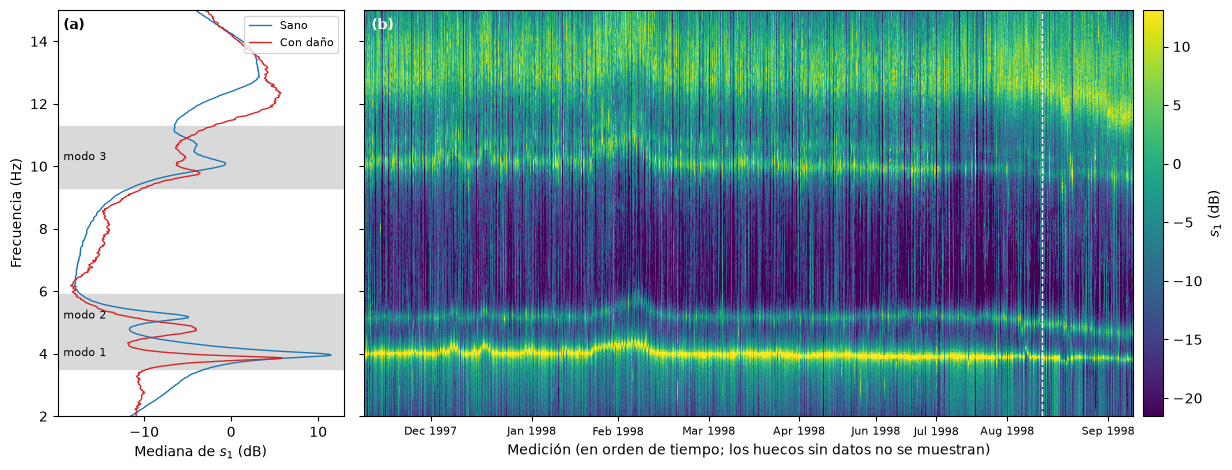

**Figura 1.** Primer valor singular $s_1$ de la matriz espectral (Ec. 1, dividida por su traza media). (a) Mediana de las mediciones del periodo sano y del periodo con daño; las bandas grises son las bandas de búsqueda de cada modo. (b) $s_1$ de cada medición, en orden de tiempo; la línea discontinua marca el inicio del daño (11.08.1998).

In [4]:
f_over = f[(f >= F_MIN) & (f <= F_MAX)]
s1_db = 10 * np.log10(data["s1_overview"][complete])
t_complete = records.loc[complete, "start"]

fig, axes = plt.subplots(1, 2, figsize=(13, 4.8), gridspec_kw={"width_ratios": [1, 3.2]}, sharey=True)
ax = axes[0]
ax.plot(np.median(s1_db[records.loc[complete, "healthy"].to_numpy()], axis=0), f_over, color="C0", lw=1, label="Sano")
ax.plot(np.median(s1_db[~records.loc[complete, "healthy"].to_numpy()], axis=0), f_over, color="C3", lw=1, label="Con daño")
for m, ((a, b), (lo, hi)) in MODES.items():
    ax.axhspan(lo, hi, color="0.85", zorder=0)
    ax.text(0.02, (lo + hi) / 2, f"modo {m}", transform=ax.get_yaxis_transform(),
            va="center", fontsize=8)
ax.set_xlabel("Mediana de $s_1$ (dB)")
ax.set_ylabel("Frecuencia (Hz)")
ax.legend(fontsize=8, loc="upper right")
ax.text(0.02, 0.98, "(a)", transform=ax.transAxes, va="top", fontweight="bold")

ax = axes[1]
mesh = ax.pcolormesh(np.arange(len(t_complete)), f_over, s1_db.T, shading="auto", cmap="viridis",
                     vmin=np.percentile(s1_db, 5), vmax=np.percentile(s1_db, 99.5))
months = pd.date_range("1997-12-01", "1998-09-01", freq="MS")
ticks = np.searchsorted(t_complete.to_numpy(), months.to_numpy())
ticks = np.minimum(ticks, len(t_complete) - 1)
has_data = (t_complete.to_numpy()[ticks] - months.to_numpy()) < np.timedelta64(3, "D")   # skip months starting in a gap
ax.set_xticks(ticks[has_data], [d.strftime("%b %Y") for d in months[has_data]], fontsize=8)
ax.axvline(np.searchsorted(t_complete.to_numpy(), DAMAGE_START.to_datetime64()), color="w", ls="--", lw=1)
ax.set_xlabel("Medición (en orden de tiempo; los huecos sin datos no se muestran)")
ax.text(0.01, 0.98, "(b)", transform=ax.transAxes, va="top", fontweight="bold", color="w")
fig.colorbar(mesh, ax=ax, label="$s_1$ (dB)", pad=0.01)
fig.tight_layout()

f_num += 1
show_figure(fig, f_num, "Primer valor singular $s_1$ de la matriz espectral (Ec. 1, dividida por su traza media). "
            "(a) Mediana de las mediciones del periodo sano y del periodo con daño; las bandas grises son las bandas de "
            "búsqueda de cada modo. (b) $s_1$ de cada medición, en orden de tiempo; la línea discontinua marca el inicio "
            "del daño (11.08.1998).")

- Se ven tres modos claros: cerca de 4.0, 5.2 y 10.0 Hz. Coinciden con los modos 1, 2 y 3 que reporta la literatura para el Z24 (3.89, 5.02 y 9.80 Hz en el estado de referencia de los PDT; Maeck y De Roeck, 2003).
- La literatura reporta un cuarto modo cerca de 10.3 Hz. Con estos 7 canales su forma es casi igual a la del modo 3 (todos los sensores verticales que quedan están en el mismo borde del tablero), así que no se puede separar y no se identifica.
- La banda ancha entre 12 y 15 Hz no es un modo bien definido; no se usa.

La Tabla 1 muestra las formas de referencia obtenidas del periodo sano (amplitud de cada canal, normalizada) y el MAC entre ellas.

In [5]:
healthy = records["healthy"].to_numpy() & complete
phi_ref = {}
for m, ((a, b), (lo, hi)) in MODES.items():
    fb = f[(f >= lo) & (f <= hi)]
    in_ref = np.flatnonzero((fb >= a) & (fb <= b))
    s1, u1 = data[f"s1_{m}"], data[f"u1_{m}"]
    k_max = in_ref[np.argmax(s1[healthy][:, in_ref], axis=1)]
    vectors = u1[healthy][np.arange(healthy.sum()), k_max]
    phi_ref[m] = np.linalg.svd(vectors, full_matrices=False)[2][0].conj()

shapes = pd.DataFrame({f"Modo {m}": np.abs(phi) / np.abs(phi).max() for m, phi in phi_ref.items()},
                      index=[f"Canal {ch}" for ch in CHANNELS])
for m in phi_ref:
    shapes.loc[f"MAC con modo {m}"] = [mac(phi_ref[n][None], phi_ref[m])[0] for n in phi_ref]

t_num += 1
show_table(shapes, t_num, "Formas de referencia de los modos (amplitud de cada canal, normalizada a 1) y MAC entre "
           "ellas. Calculadas con las mediciones del periodo sano, con los canales normalizados (Ec. 2): sirven para "
           "seguir cada modo, no son las formas modales físicas.")

**Tabla 1.** Formas de referencia de los modos (amplitud de cada canal, normalizada a 1) y MAC entre ellas. Calculadas con las mediciones del periodo sano, con los canales normalizados (Ec. 2): sirven para seguir cada modo, no son las formas modales físicas.

,Modo 1,Modo 2,Modo 3
Canal 03,0.96,0.69,0.85
Canal 05,1.00,0.53,1.00
Canal 06,0.99,0.79,0.80
Canal 07,0.10,0.42,0.50
Canal 12,0.99,0.72,0.80
Canal 14,0.71,0.99,0.50
Canal 16,0.16,1.00,0.59
MAC con modo 1,1.00,0.08,0.25
MAC con modo 2,0.08,1.00,0.26
MAC con modo 3,0.25,0.26,1.00


- El MAC entre las formas de los tres modos es menor que 0.3, así que se distinguen bien entre sí.
- En el modo 2 dominan los canales transversales 14 y 16: es el modo lateral. En el modo 1 el canal transversal 16 casi no participa: es un modo de flexión vertical.

---
<a id="sec5"></a>
## 5. Frecuencias naturales de cada medición

Se aplica el paso 2 de la sección 2 a todas las mediciones. La tabla de resultados se guarda en `results/ems_natural_frequencies.csv`, con una fila por medición:
- `code`: nombre de la medición (`WWDHH`).
- `start`: fecha y hora de inicio.
- `healthy`: `True` antes del inicio del daño (11.08.1998, 13:15).
- `f1`, `f2`, `f3`: frecuencia de cada modo en Hz (vacía si no se identificó).
- `mac1`, `mac2`, `mac3`: MAC entre la forma medida y la de referencia.

In [6]:
def track_mode(m):
    (_, (lo, hi)) = MODES[m]
    fb = f[(f >= lo) & (f <= hi)]
    s1_all, u1_all = data[f"s1_{m}"], data[f"u1_{m}"]
    freqs = np.full(len(records), np.nan)
    macs = np.full(len(records), np.nan)
    for r in np.flatnonzero(complete):
        s1 = s1_all[r]
        mac_r = mac(u1_all[r], phi_ref[m])
        peaks = [k for k in range(1, len(fb) - 1)
                 if s1[k] >= s1[k - 1] and s1[k] >= s1[k + 1] and mac_r[k] >= MAC_MIN]
        if not peaks:
            continue
        k = max(peaks, key=lambda k: s1[k])
        freqs[r] = refine_peak(fb, s1, k)
        macs[r] = mac_r[k]
    return freqs, macs


frequencies = records[["code", "start", "healthy"]].copy()
for m in MODES:
    frequencies[f"f{m}"], frequencies[f"mac{m}"] = track_mode(m)

RESULTS_DIR.mkdir(exist_ok=True)
frequencies.to_csv(RESULTS_DIR / "ems_natural_frequencies.csv", index=False)

t_num += 1
show_table(frequencies, t_num, "Frecuencias naturales identificadas en cada medición del EMS (primeras y últimas filas).",
           precision=3, n_rows=5)

**Tabla 2.** Frecuencias naturales identificadas en cada medición del EMS (primeras y últimas filas).

,code,start,healthy,f1,mac1,f2,mac2,f3,mac3
0,01C14,1997-11-10 14:00:13,True,3.983,0.907,5.131,0.890,9.651,0.731
1,01C15,1997-11-10 15:00:11,True,3.994,0.957,5.170,0.857,9.978,0.771
2,01C16,1997-11-10 16:00:10,True,3.978,0.995,5.053,0.723,10.106,0.754
3,01C17,1997-11-10 17:00:10,True,3.975,0.971,4.980,0.779,10.139,0.838
4,01C18,1997-11-10 18:00:10,True,3.958,0.946,nan,nan,10.251,0.816
...,...,...,...,...,...,...,...,...,...
5648,44F09,1998-09-10 09:00:10,False,3.844,0.931,4.667,0.968,9.671,0.887
5649,44F10,1998-09-10 10:00:10,False,3.846,0.899,4.679,0.970,9.783,0.774
5650,44F11,1998-09-10 11:00:10,False,3.838,0.944,4.656,0.956,9.745,0.876
5651,44F12,1998-09-10 12:00:10,False,3.840,0.917,4.704,0.963,9.742,0.724


In [7]:
rows = []
for period, mask in [("Sano", frequencies["healthy"]), ("Con daño", ~frequencies["healthy"])]:
    for m in MODES:
        fm = frequencies.loc[mask, f"f{m}"]
        rows.append({"Periodo": period, "Modo": m, "Mediciones": mask.sum(), "Identificadas (%)": 100 * fm.notna().mean(),
                     "Media (Hz)": fm.mean(), "Desv. est. (Hz)": fm.std(), "Mín. (Hz)": fm.min(), "Máx. (Hz)": fm.max()})
summary = pd.DataFrame(rows)

t_num += 1
show_table(summary, t_num, "Resumen de las frecuencias identificadas en el periodo sano y en el periodo con daño.",
           precision=3, hide_index=True)

**Tabla 3.** Resumen de las frecuencias identificadas en el periodo sano y en el periodo con daño.

Periodo,Modo,Mediciones,Identificadas (%),Media (Hz),Desv. est. (Hz),Mín. (Hz),Máx. (Hz)
Sano,1,4979,98.855,4.002,0.104,3.533,4.398
Sano,2,4979,98.192,5.195,0.121,4.668,5.857
Sano,3,4979,96.385,10.144,0.254,9.358,11.228
Con daño,1,674,84.718,3.855,0.046,3.541,4.131
Con daño,2,674,98.220,4.798,0.123,4.582,5.249
Con daño,3,674,79.970,9.749,0.123,9.317,9.984


La Figura 2 muestra las tres frecuencias a lo largo de todo el monitoreo y la Figura 3, un acercamiento a los dos últimos meses.

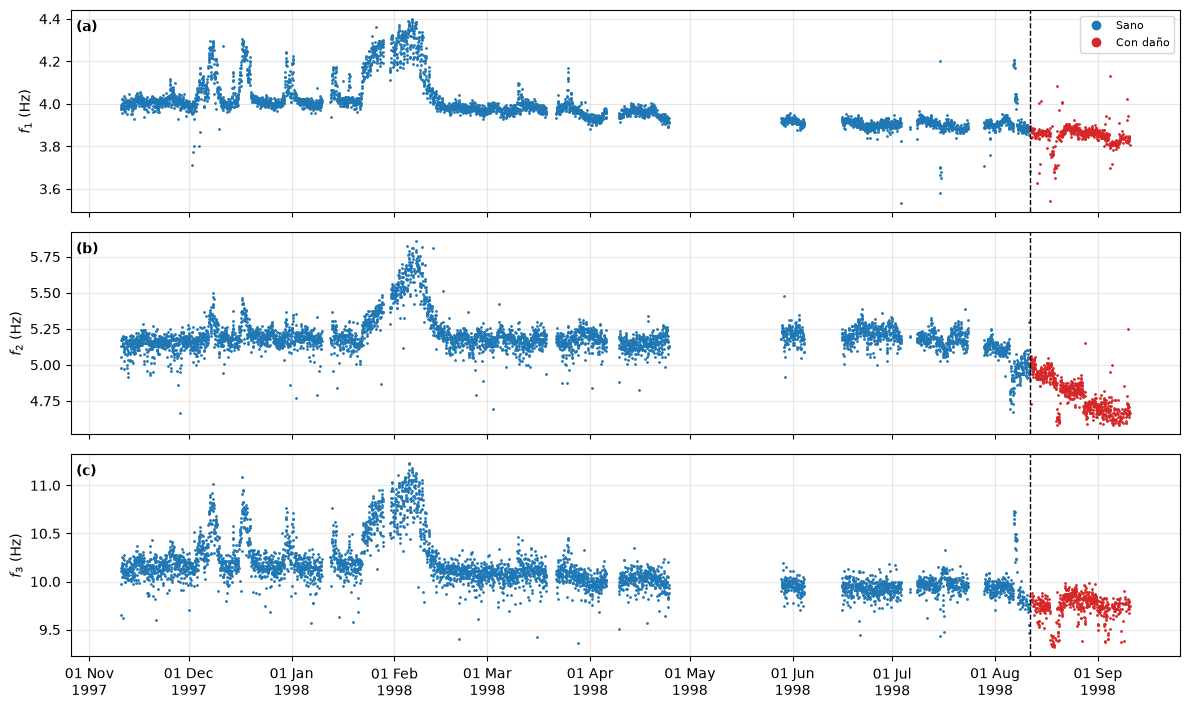

**Figura 2.** Frecuencias naturales identificadas en cada medición del EMS: (a) modo 1, (b) modo 2 y (c) modo 3. Azul: periodo sano; rojo: periodo con daño. La línea discontinua marca el primer descenso de la pila (11.08.1998).

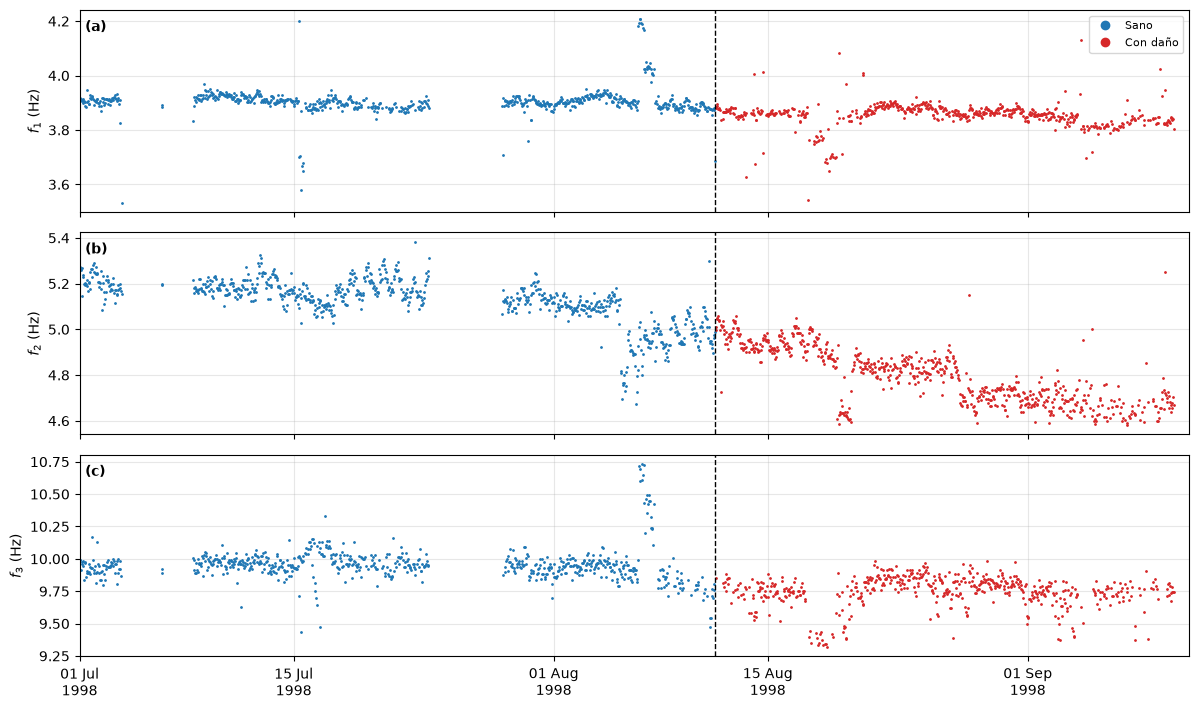

**Figura 3.** Acercamiento a la Figura 2 entre el 01.07.1998 y el final del monitoreo (10.09.1998).

In [8]:
def plot_frequencies(df, xlim=None):
    fig, axes = plt.subplots(len(MODES), 1, figsize=(12, 2.4 * len(MODES)), sharex=True)
    for i, (ax, m) in enumerate(zip(axes, MODES)):
        for period, mask, color in [("Sano", df["healthy"], "C0"), ("Con daño", ~df["healthy"], "C3")]:
            ax.plot(df.loc[mask, "start"], df.loc[mask, f"f{m}"], ".", ms=2, color=color, label=period)
        ax.axvline(DAMAGE_START, color="k", ls="--", lw=1)
        ax.set_ylabel(f"$f_{m}$ (Hz)")
        ax.grid(alpha=0.3)
        ax.text(0.005, 0.95, f"({chr(97 + i)})", transform=ax.transAxes, va="top", fontweight="bold")
    axes[0].legend(markerscale=6, fontsize=8, loc="upper right")
    if xlim is not None:
        axes[-1].set_xlim(xlim)
    axes[-1].xaxis.set_major_formatter(mdates.DateFormatter("%d %b\n%Y"))
    fig.tight_layout()
    return fig


fig = plot_frequencies(frequencies)
f_num += 1
show_figure(fig, f_num, "Frecuencias naturales identificadas en cada medición del EMS: (a) modo 1, (b) modo 2 y (c) modo 3. "
            "Azul: periodo sano; rojo: periodo con daño. La línea discontinua marca el primer descenso de la pila "
            "(11.08.1998).")

late = frequencies[frequencies["start"] >= "1998-07-01"]
fig = plot_frequencies(late, xlim=(pd.Timestamp("1998-07-01"), frequencies["start"].max() + pd.Timedelta("1D")))
f_num += 1
show_figure(fig, f_num, "Acercamiento a la Figura 2 entre el 01.07.1998 y el final del monitoreo (10.09.1998).")

### Distribución de las frecuencias en el estado sano

La Figura 4 muestra el histograma de cada frecuencia con las mediciones del periodo sano (antes del 11.08.1998, 13:15). Solo se cuentan las mediciones en que se identificó el modo.

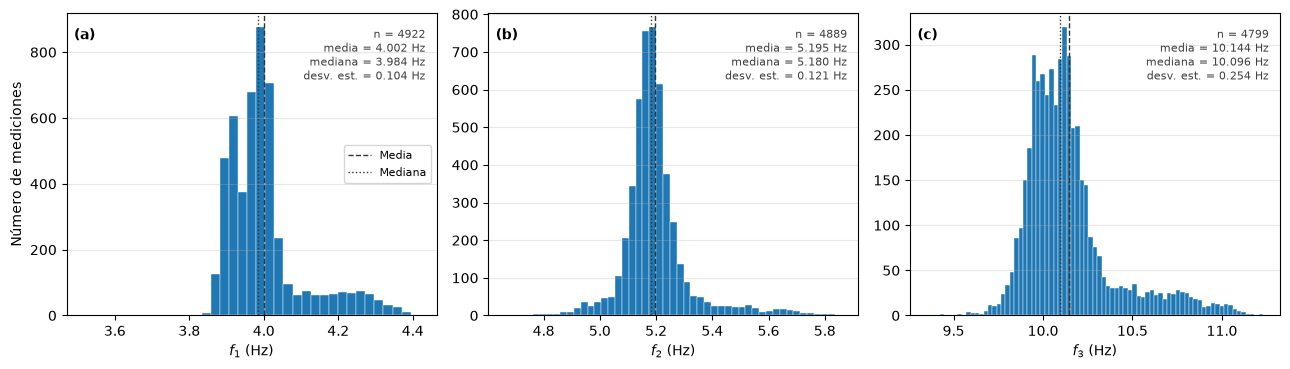

**Figura 4.** Histograma de las frecuencias naturales identificadas en el periodo sano: (a) modo 1, (b) modo 2 y (c) modo 3. Ancho de clase: 0.024 Hz, igual a la resolución en frecuencia. La línea discontinua marca la media y la punteada, la mediana.

In [9]:
healthy_freqs = frequencies[frequencies["healthy"]]

fig, axes = plt.subplots(1, len(MODES), figsize=(13, 3.8))
for i, (ax, m) in enumerate(zip(axes, MODES)):
    x = healthy_freqs[f"f{m}"].dropna()
    bw = f[1] - f[0]   # bin width = frequency resolution, to avoid picket-fence artifacts
    bins = np.arange(np.floor(x.min() / bw) * bw, x.max() + bw, bw)
    ax.hist(x, bins=bins, color="C0", edgecolor="white", linewidth=0.3)
    ax.axvline(x.mean(), color="0.2", lw=1, ls="--", label="Media")
    ax.axvline(x.median(), color="0.2", lw=1, ls=":", label="Mediana")
    ax.text(0.97, 0.95, f"n = {len(x)}\nmedia = {x.mean():.3f} Hz\nmediana = {x.median():.3f} Hz\n"
            f"desv. est. = {x.std():.3f} Hz", transform=ax.transAxes, ha="right", va="top", fontsize=8, color="0.25")
    ax.set_xlabel(f"$f_{m}$ (Hz)")
    ax.grid(axis="y", alpha=0.3)
    ax.text(0.02, 0.95, f"({chr(97 + i)})", transform=ax.transAxes, va="top", fontweight="bold")
axes[0].set_ylabel("Número de mediciones")
axes[0].legend(fontsize=8, loc="center right")
fig.tight_layout()

f_num += 1
show_figure(fig, f_num, "Histograma de las frecuencias naturales identificadas en el periodo sano: (a) modo 1, "
            "(b) modo 2 y (c) modo 3. Ancho de clase: 0.024 Hz, igual a la resolución en frecuencia. La línea discontinua "
            "marca la media y la punteada, la mediana.")

### Distribución por estación del año

Las frecuencias del periodo sano se separan por estación meteorológica (las que usa MeteoSwiss): otoño (septiembre a noviembre), invierno (diciembre a febrero), primavera (marzo a mayo) y verano (junio a agosto). Cada estación cubre solo los días con mediciones:

- **Otoño 1997:** desde el 10.11.1997 (inicio del monitoreo).
- **Invierno 1997–98:** completo.
- **Primavera 1998:** con un hueco del 24.04 al 28.05.1998.
- **Verano 1998:** hasta el 11.08.1998, 13:15 (inicio del daño).

El otoño de 1998 no se incluye porque todas sus mediciones son del periodo con daño.

La Tabla 4 resume cada modo en cada estación y la Figura 5 muestra los histogramas. En cada fila (un modo) los cuatro paneles comparten el eje horizontal, para comparar las estaciones.

In [10]:
SEASON_OF_MONTH = {9: "Otoño", 10: "Otoño", 11: "Otoño", 12: "Invierno", 1: "Invierno", 2: "Invierno",
                   3: "Primavera", 4: "Primavera", 5: "Primavera", 6: "Verano", 7: "Verano", 8: "Verano"}
SEASONS = ["Otoño 1997", "Invierno 1997–98", "Primavera 1998", "Verano 1998"]


def season_label(t):
    # Meteorological season with its year; winter is named after the two years it spans
    season = SEASON_OF_MONTH[t.month]
    if season == "Invierno":
        first = t.year - 1 if t.month in (1, 2) else t.year
        return f"Invierno {first}–{str(first + 1)[2:]}"
    return f"{season} {t.year}"


healthy_freqs = frequencies[frequencies["healthy"]].copy()
healthy_freqs["season"] = healthy_freqs["start"].apply(season_label)

rows = []
for m in MODES:
    for s in SEASONS:
        x = healthy_freqs.loc[healthy_freqs["season"] == s, f"f{m}"].dropna()
        rows.append({"Modo": m, "Estación": s, "Mediciones": len(x), "Media (Hz)": x.mean(),
                     "Desv. est. (Hz)": x.std(), "Mín. (Hz)": x.min(), "Máx. (Hz)": x.max()})
season_summary = pd.DataFrame(rows)

t_num += 1
show_table(season_summary, t_num, "Frecuencias del periodo sano por modo y estación del año.", precision=3, hide_index=True)

**Tabla 4.** Frecuencias del periodo sano por modo y estación del año.

Modo,Estación,Mediciones,Media (Hz),Desv. est. (Hz),Mín. (Hz),Máx. (Hz)
1,Otoño 1997,490,4.009,0.023,3.927,4.119
1,Invierno 1997–98,2040,4.076,0.113,3.711,4.398
1,Primavera 1998,1227,3.965,0.031,3.881,4.170
1,Verano 1998,1165,3.906,0.041,3.533,4.207
2,Otoño 1997,481,5.144,0.063,4.668,5.285
2,Invierno 1997–98,1980,5.250,0.146,4.770,5.857
2,Primavera 1998,1214,5.167,0.061,4.691,5.477
2,Verano 1998,1214,5.156,0.101,4.671,5.387
3,Otoño 1997,477,10.148,0.103,9.597,10.427
3,Invierno 1997–98,1989,10.315,0.286,9.399,11.228


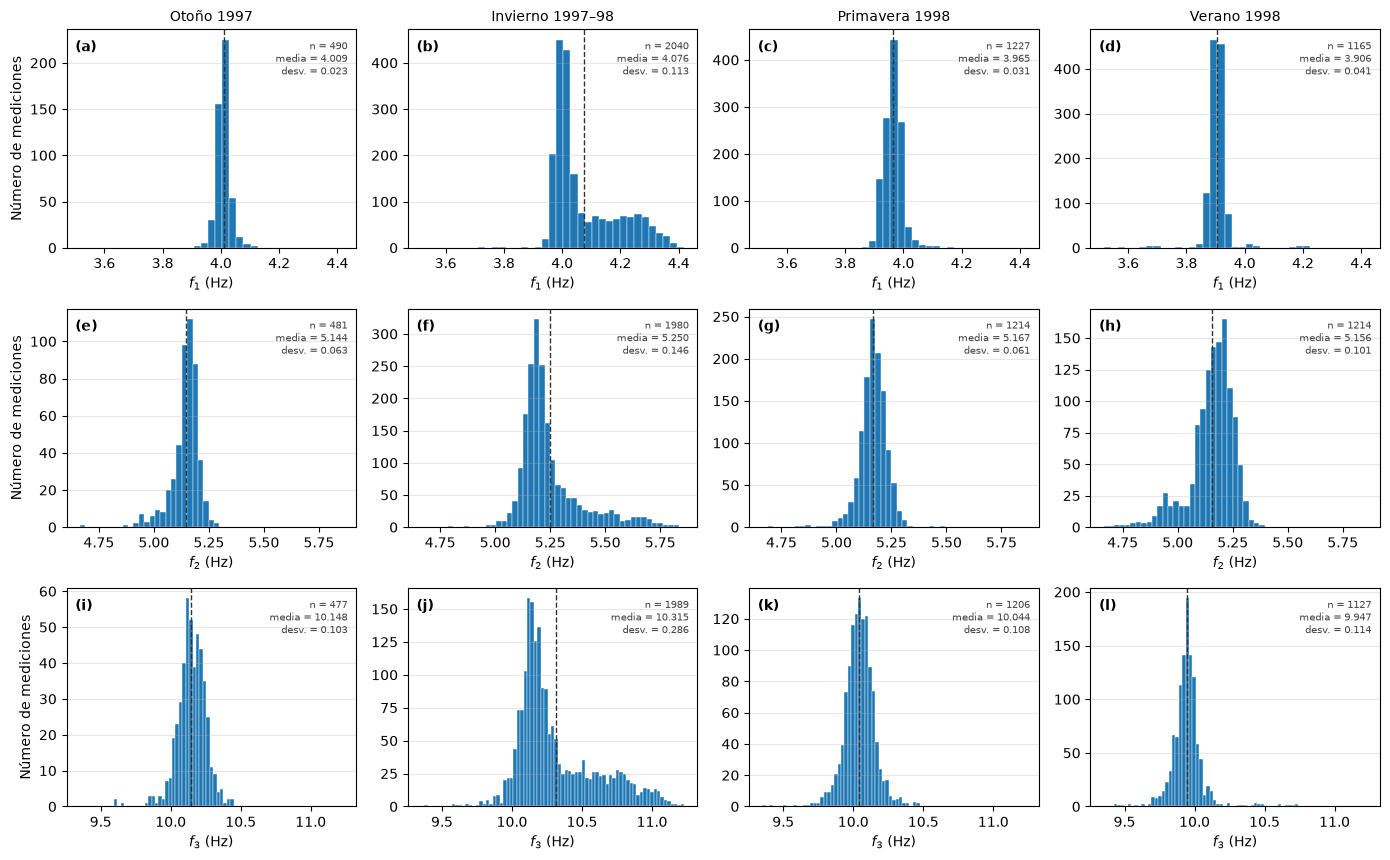

**Figura 5.** Histogramas de las frecuencias del periodo sano por estación del año (columnas) y modo (filas): (a)–(d) modo 1, (e)–(h) modo 2 e (i)–(l) modo 3. Los paneles de una misma fila comparten el eje horizontal. Ancho de clase: 0.024 Hz (la resolución en frecuencia). La línea discontinua marca la media.

In [11]:
df_bin = f[1] - f[0]   # bin width = frequency resolution, to avoid picket-fence artifacts
fig, axes = plt.subplots(len(MODES), len(SEASONS), figsize=(14, 2.9 * len(MODES)), sharex="row")
for i, m in enumerate(MODES):
    all_x = healthy_freqs[f"f{m}"].dropna()
    bins = np.arange(np.floor(all_x.min() / df_bin) * df_bin, all_x.max() + df_bin, df_bin)
    for j, s in enumerate(SEASONS):
        ax = axes[i, j]
        x = healthy_freqs.loc[healthy_freqs["season"] == s, f"f{m}"].dropna()
        ax.hist(x, bins=bins, color="C0", edgecolor="white", linewidth=0.3)
        ax.axvline(x.mean(), color="0.2", lw=1, ls="--")
        ax.text(0.97, 0.95, f"n = {len(x)}\nmedia = {x.mean():.3f}\ndesv. = {x.std():.3f}",
                transform=ax.transAxes, ha="right", va="top", fontsize=7.5, color="0.25")
        ax.grid(axis="y", alpha=0.3)
        ax.text(0.03, 0.95, f"({chr(97 + i * len(SEASONS) + j)})", transform=ax.transAxes, va="top", fontweight="bold")
        if i == 0:
            ax.set_title(s, fontsize=10)
        if j == 0:
            ax.set_ylabel("Número de mediciones")
        ax.set_xlabel(f"$f_{m}$ (Hz)")
fig.tight_layout()

f_num += 1
show_figure(fig, f_num, "Histogramas de las frecuencias del periodo sano por estación del año (columnas) y modo (filas): "
            "(a)–(d) modo 1, (e)–(h) modo 2 e (i)–(l) modo 3. Los paneles de una misma fila comparten el eje horizontal. "
            "Ancho de clase: 0.024 Hz (la resolución en frecuencia). La línea discontinua marca la media.")

- **Otoño, primavera y verano:** distribuciones estrechas y con un solo pico. La media baja a medida que sube la temperatura; por ejemplo, el modo 1 pasa de 4.01 Hz en otoño a 3.97 Hz en primavera y 3.91 Hz en verano.
- **Invierno:** cada modo tiene un pico principal, en el mismo lugar que en otoño, y una cola larga hacia frecuencias altas (hasta 4.4, 5.9 y 11.2 Hz). La cola corresponde a las horas con helada: el 39 % de las horas del invierno estuvieron bajo 0 °C. Por eso el invierno tiene la mayor dispersión.
- **Verano, modo 2:** hay una cola de valores bajos (4.7 a 5.0 Hz). Son 108 mediciones, todas entre el 4 y el 11 de agosto de 1998: justo después de la primera medición de referencia de los PDT (04–05.08) y antes del primer descenso de la pila. Probablemente reflejan los trabajos de instalación del sistema para bajar la pila, así que esas horas no representan del todo al puente sano. Sin ellas, el modo 2 en verano tiene una media de 5.173 Hz y una desviación estándar de 0.087 Hz.

---
<a id="sec6"></a>
## 6. Observaciones

- **Qué se obtuvo:** la frecuencia de los modos 1, 2 y 3 en cada una de las 5652 mediciones completas. En el periodo sano se identificaron en el 99 %, 98 % y 96 % de las mediciones; en el periodo con daño, en el 85 %, 98 % y 80 % (Tabla 3).
- **Periodo sano:** las frecuencias medias son 4.00, 5.20 y 10.14 Hz. No son constantes: suben con claridad en los periodos de mucho frío (diciembre de 1997 y, sobre todo, fines de enero y febrero de 1998), cuando el modo 1 llega a 4.4 Hz, el modo 2 a 5.9 Hz y el modo 3 a 11.2 Hz (Figuras 2 y 5). La literatura del Z24 lo atribuye a la rigidización del asfalto y del suelo congelados. Por eso, para comparar el puente sano con el dañado, hay que tener en cuenta la temperatura (columna `AT` o temperaturas del tablero del EMS).
- **Periodo con daño:** las frecuencias medias bajan a 3.86, 4.80 y 9.75 Hz. El modo 2 es el que más cambia: baja por escalones de unos 5.2 Hz a unos 4.65 Hz al final (Figura 3b).
- **Cambios antes del 11.08.1998:** el modo 2 ya baja de 5.1 a unos 4.9 Hz entre el 7 y el 10 de agosto. Probablemente corresponde a la instalación del sistema para bajar la pila, que obligó a cortar parte de la pila Koppigen (Apéndice D de `C11-Appendices.pdf`). En esos días hay también unas horas con los modos 1 y 3 anormalmente altos.
- **Descenso máximo de la pila:** entre el 18 y el 19 de agosto las tres frecuencias caen de forma brusca (por ejemplo, el modo 2 a unos 4.6 Hz) y luego se recuperan en parte. Coincide con el descenso de 95 mm del 18.08 y la pila vuelta a subir el 19.08 (Tabla 8 del Apéndice F).

**Limitaciones:**
- Solo se identifican 3 modos. El cuarto modo de la literatura (cerca de 10.3 Hz) no se puede separar del modo 3 con los sensores que quedan.
- El canal 10 no se usa, y el canal 03 está muerto en un 3 % de las horas (ahí se identifica con 6 canales).
- Las señales se saturan al pasar vehículos pesados; esos tramos quedan dentro del cálculo.
- El modo 3 es el más débil y el que más dispersión tiene.
- El EMS no indica qué escenario de daño se estaba aplicando en cada hora; solo se marca el inicio del daño.